**baseline modelling**
- relevant dataset only
- one hot encoding categorical features
- sample balancing ???
- logistic regression
- random forest

In [1]:
from helper_functions.data_processing import get_cleaned_data
data, numerical_cols, categorical_cols = get_cleaned_data()
from helper_functions.model_building import *

Missing values before imputation: 30

Filled out missing values.

Missing values after imputation: 0

In [2]:
preprocessor = get_preprocessor(data, numerical_cols, categorical_cols)
X_train, X_test, y_train, y_test = get_train_test_data(data)

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64


## Class Balancing

### With PCA decomposition

In [3]:
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
n_components = 3

# Define oversampler (SMOTE)
oversampler = SMOTE(random_state=42)

# Random Forest pipeline with oversampling
rf_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('oversample', oversampler),
    ('pca', PCA(n_components=n_components)),
    ('classifier', RandomForestClassifier(random_state=42))
])

# SVC pipeline with oversampling
svc_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('oversample', oversampler),
    ('pca', PCA(n_components=n_components)),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

# Train and evaluate Random Forest
rf_pipeline.fit(X_train, y_train)
rf_predictions = rf_pipeline.predict(X_test)
print("Random Forest Results:")
print(classification_report(y_test, rf_predictions))

# Train and evaluate SVC
svc_pipeline.fit(X_train, y_train)
svc_predictions = svc_pipeline.predict(X_test)
print("SVC Results:")
print(classification_report(y_test, svc_predictions))

from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': [0.01, 0.1, 1]
}

# grid_search = GridSearchCV(svc_pipeline, param_grid, scoring='f1', cv=5)
# grid_search.fit(X_train, y_train)
# print(grid_search.best_params_)


Random Forest Results:
              precision    recall  f1-score   support

           0       0.96      0.74      0.84       514
           1       0.05      0.29      0.09        24

    accuracy                           0.72       538
   macro avg       0.50      0.52      0.46       538
weighted avg       0.92      0.72      0.80       538

SVC Results:
              precision    recall  f1-score   support

           0       0.96      0.57      0.72       514
           1       0.06      0.54      0.10        24

    accuracy                           0.57       538
   macro avg       0.51      0.56      0.41       538
weighted avg       0.92      0.57      0.69       538



Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


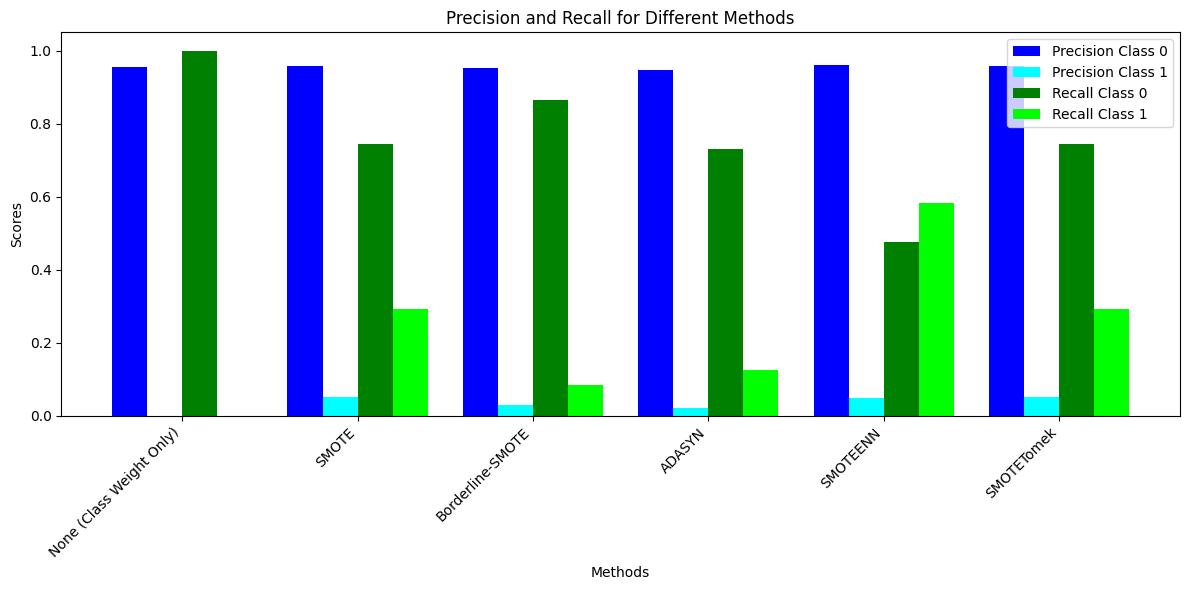

In [4]:
results_rfc = evaluate_methods(data, preprocessor, PCA(n_components=n_components), RandomForestClassifier(class_weight='balanced', random_state=42))

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


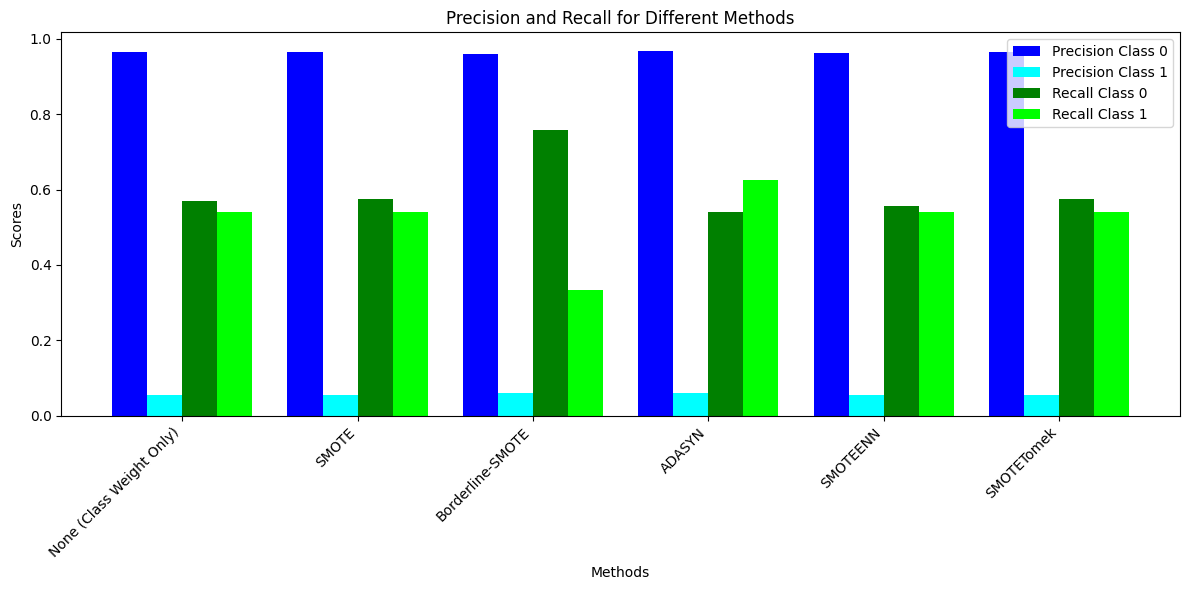

In [5]:
results_svc = evaluate_methods(data, preprocessor, PCA(n_components=n_components), SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42))

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


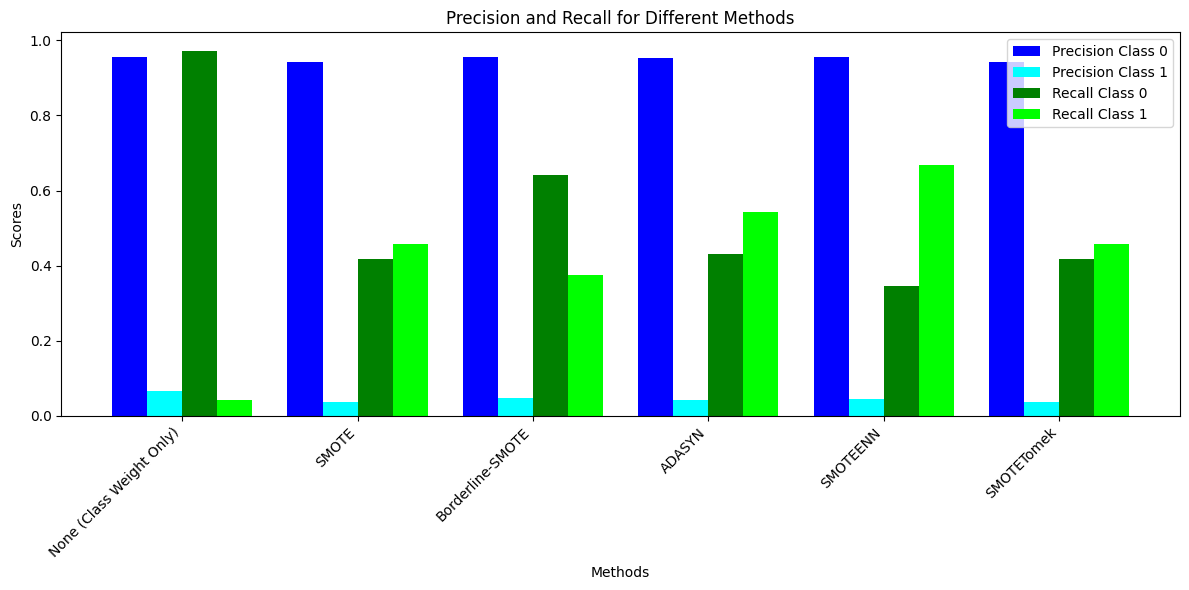

In [6]:
from xgboost import XGBClassifier
# Calculate scale_pos_weight
pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
results_xgb = evaluate_methods(
    data,
    preprocessor, 
    PCA(n_components=n_components), 
    XGBClassifier(scale_pos_weight=pos_weight, eval_metric='logloss', random_state=42)
    )


In [7]:
plot_comparison_results(results_rfc, results_svc, results_xgb)

### Without PCA decomposition

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)


/Users/uche/Sepsis_Hackathon/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.



Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


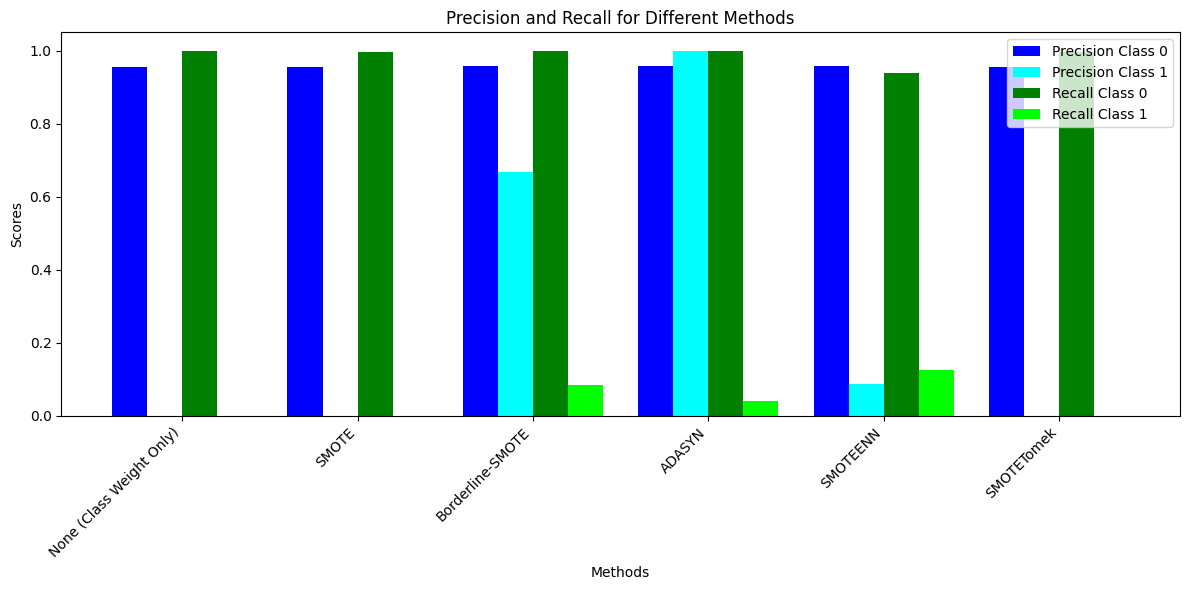

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


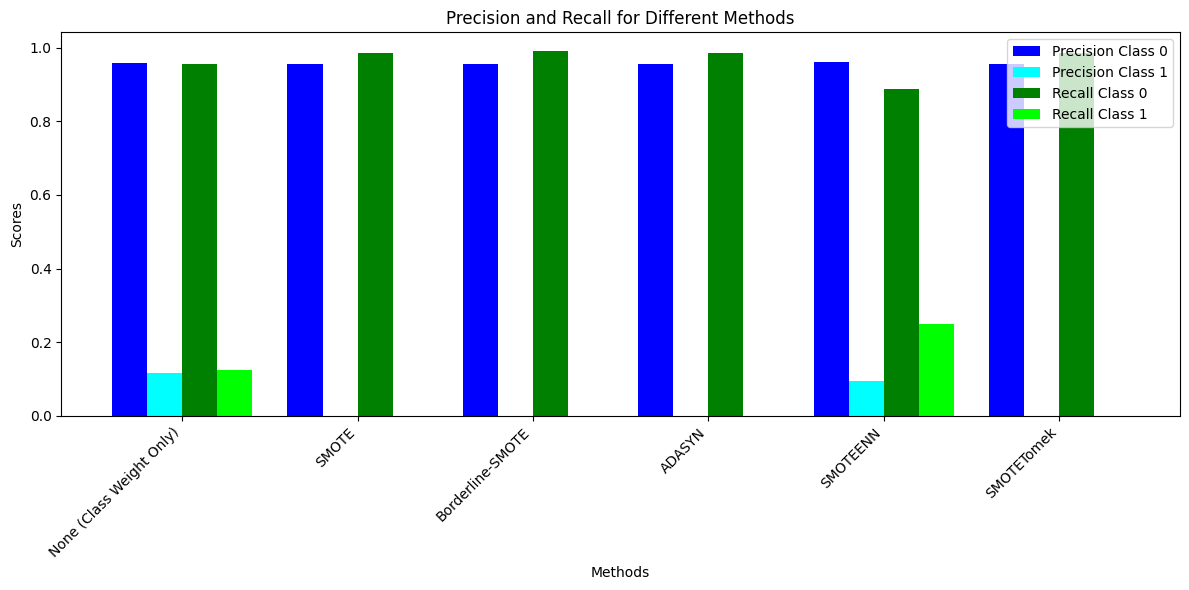

Class distribution in training data:
inhospital_mortality
0    0.955773
1    0.044227
Name: proportion, dtype: float64

Class distribution in test data:
inhospital_mortality
0    0.95539
1    0.04461
Name: proportion, dtype: float64
Evaluating: None (Class Weight Only)
Evaluating: SMOTE
Evaluating: Borderline-SMOTE
Evaluating: ADASYN
Evaluating: SMOTEENN
Evaluating: SMOTETomek


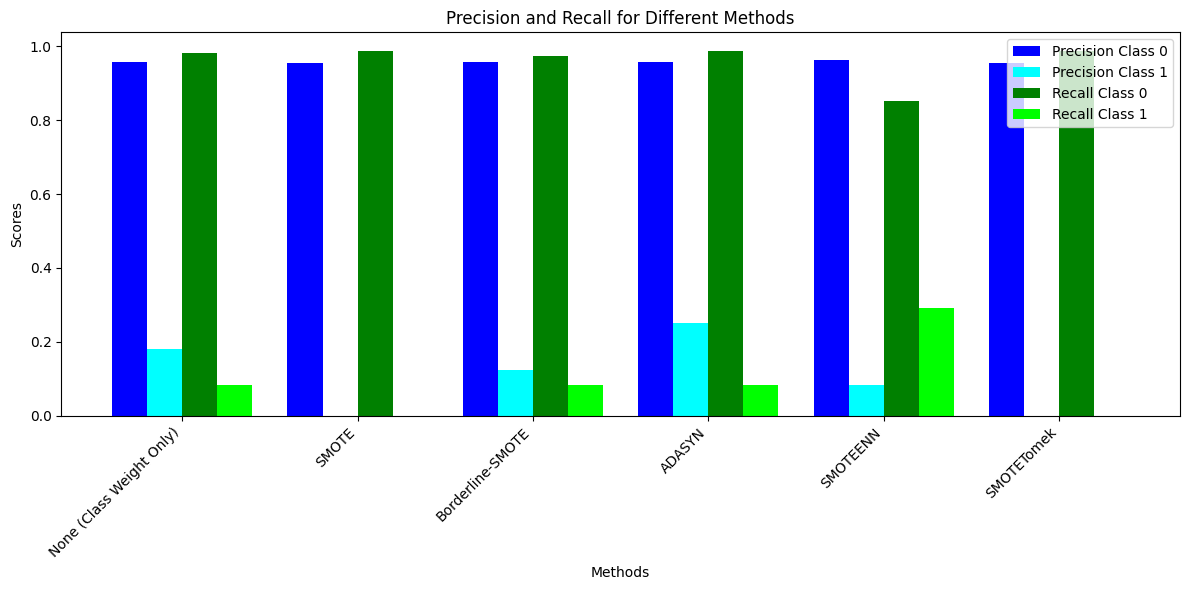

In [10]:
results_rfc_sans_pca = evaluate_methods(data, preprocessor, None, classifier=RandomForestClassifier(class_weight='balanced', random_state=42))
results_svc_sans_pca = evaluate_methods(data, preprocessor, None, classifier=SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42))
results_xgb_sans_pca = evaluate_methods(data, preprocessor,  None, classifier=XGBClassifier(scale_pos_weight=pos_weight, eval_metric='logloss', random_state=42) )
plot_comparison_results(results_rfc_sans_pca, results_svc_sans_pca, results_xgb_sans_pca)